In [ ]:
## 1. Librerías

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
# Solo si se usa google colab ---
from google.colab import drive

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression, Ridge

# Solo si se usa google colab ---
drive.mount('/content/drive')

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

Mounted at /content/drive


In [ ]:
## 2. Carga de datos

In [ ]:
solicitudes_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_train.csv")
comportamiento = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/comportamiento_bancario.csv")
solicitudes_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_test.csv")

#Configurar ruta, lo veniamos usando con colab
#solicitudes_train = pd.read_csv("solicitudes_train.csv")
#comportamiento = pd.read_csv("comportamiento_bancario.csv")
#solicitudes_test = pd.read_csv("solicitudes_test.csv")


In [ ]:
## 3. Features de comportamiento bancario

In [ ]:
solicitudes_completas = pd.concat([solicitudes_train, solicitudes_test])

historial_cruzado = comportamiento.merge(
    solicitudes_completas[["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud"]],
    on="ID_Usuario"
)

historial_cruzado["Fecha_Solicitud"] = pd.to_datetime(historial_cruzado["Fecha_Solicitud"])
historial_cruzado["Mes_Referencia"] = pd.to_datetime(historial_cruzado["Mes_Referencia"])

historial_valido = historial_cruzado[historial_cruzado["Mes_Referencia"] < historial_cruzado["Fecha_Solicitud"]]
historial_valido = historial_valido.sort_values(["ID_Solicitud", "Mes_Referencia"])

historial_valido["atraso"] = (historial_valido["Dias_Atraso_Otras_Deudas"] > 0).astype(int)
g = historial_valido.groupby("ID_Solicitud")

In [ ]:
metricas_bancarias = g.agg(
    Saldo_Promedio=("Saldo_Promedio_Mensual", "mean"),
    Saldo_Std=("Saldo_Promedio_Mensual", "std"),
    Saldo_Ultimo=("Saldo_Promedio_Mensual", "last"),
    Atraso_Promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    Frac_Meses_Atraso=("atraso", "mean"),
    Atraso_Ultimo=("Dias_Atraso_Otras_Deudas", "last"),
)

for n in (3, 6):
    t = g.tail(n).groupby("ID_Solicitud").agg(**{
        f"Saldo_{n}m": ("Saldo_Promedio_Mensual", "mean"),
        f"Atraso_Prom_{n}m": ("Dias_Atraso_Otras_Deudas", "mean"),
        f"Atraso_Max_{n}m": ("Dias_Atraso_Otras_Deudas", "max"),
        f"Frac_Atraso_{n}m": ("atraso", "mean"),
    })
    metricas_bancarias = metricas_bancarias.join(t)

In [ ]:
metricas_bancarias["Saldo_CV"] = metricas_bancarias["Saldo_Std"] / metricas_bancarias["Saldo_Promedio"].replace(0, np.nan)

metricas_bancarias["Aceleracion_Atraso"] = metricas_bancarias["Atraso_Prom_3m"] / metricas_bancarias["Atraso_Promedio"].replace(0, 1)

metricas_bancarias["Tendencia_Saldo"] = metricas_bancarias["Saldo_3m"] / metricas_bancarias["Saldo_6m"].replace(0, np.nan)
metricas_bancarias["Tendencia_Atraso"] = metricas_bancarias["Atraso_Prom_3m"] - metricas_bancarias["Atraso_Prom_6m"]

In [ ]:
def racha_sin_atraso(sub_df):
    atrasos = sub_df["Dias_Atraso_Otras_Deudas"].values[::-1]
    racha = 0
    for a in atrasos:
        if a == 0:
            racha += 1
        else:
            break
    return racha

racha_df = g.apply(racha_sin_atraso).rename("Racha_Sin_Atraso").reset_index()
metricas_bancarias = metricas_bancarias.reset_index().merge(racha_df, on="ID_Solicitud")

/tmp/ipykernel_697/755868396.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  racha_df = g.apply(racha_sin_atraso).rename("Racha_Sin_Atraso").reset_index()


In [ ]:
## 4. Dataset final de train y test

In [ ]:
solicitudes_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_train.csv")
solicitudes_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_test.csv")

# Configurar rutas
#solicitudes_train = pd.read_csv("solicitudes_train.csv")
#solicitudes_test = pd.read_csv("solicitudes_test.csv")

solicitudes_train = solicitudes_train.merge(metricas_bancarias, on="ID_Solicitud", how="left")
solicitudes_test = solicitudes_test.merge(metricas_bancarias, on="ID_Solicitud", how="left")

for df in (solicitudes_train, solicitudes_test):
    df["Monto_sobre_Ingreso"] = df["Monto_Solicitado"] / df["Ingreso_Mensual"]
    df["Monto_sobre_Saldo"] = df["Monto_Solicitado"] / df["Saldo_Promedio"].replace(0, np.nan)

solicitudes_train = pd.get_dummies(solicitudes_train, columns=["Motivo_Prestamo"], drop_first=True)
solicitudes_test = pd.get_dummies(solicitudes_test, columns=["Motivo_Prestamo"], drop_first=True)

print("Dimensiones Train:", solicitudes_train.shape)
print("Dimensiones Test:", solicitudes_test.shape)

Dimensiones Train: (32416, 34)
Dimensiones Test: (3061, 33)


In [ ]:
## 5. Features, target y split

In [ ]:
columnas_a_borrar = ["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud", "Estado_Final"]
cols_monto = ["Monto_Solicitado", "Monto_sobre_Ingreso", "Monto_sobre_Saldo"]
X = solicitudes_train.drop(columns=columnas_a_borrar + cols_monto)
y = solicitudes_train["Estado_Final"]

In [ ]:
fechas = pd.to_datetime(solicitudes_train["Fecha_Solicitud"])
corte = pd.Timestamp("2025-10-01")

idx_tr = np.where(fechas < corte)[0]
idx_val = np.where(fechas >= corte)[0]

usuarios_tr = set(solicitudes_train.iloc[idx_tr]["ID_Usuario"])
mask = ~solicitudes_train.iloc[idx_val]["ID_Usuario"].isin(usuarios_tr).values
idx_val = idx_val[mask]

X_train, X_val = X.iloc[idx_tr], X.iloc[idx_val]
y_train, y_val = y.iloc[idx_tr], y.iloc[idx_val]

In [ ]:
## 6. Entrenamiento del modelo

In [ ]:
#modelo = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
#modelo.fit(X_train, y_train)
#modelo = HistGradientBoostingClassifier(
#   learning_rate=0.05, max_iter=300, max_depth=4,
#   l2_regularization=1.0, random_state=42
#)
#modelo = HistGradientBoostingClassifier(
#   learning_rate=0.05, max_iter=300, max_depth=8,
#   l2_regularization=1.0, random_state=42
#)
#logit = Pipeline([
 #   ("imp", SimpleImputer(strategy="median")),
 #   ("sc", StandardScaler()),
  #  ("lr", LogisticRegression(C=0.3, max_iter=2000)),
#])

#ensemble = VotingClassifier(
  #  estimators=[("hgb", modelo), ("logit", logit)],
 #   voting="soft", weights=[2, 1],
#)
#ensemble.fit(X_train.replace([np.inf, -np.inf], np.nan), y_train)

#probabilidades_val_hgb = modelo.predict_proba(X_val)[:, 1]
#probabilidades_val = ensemble.predict_proba(X_val.replace([np.inf, -np.inf], np.nan))[:, 1]

modelo = HistGradientBoostingClassifier(
   learning_rate=0.05, max_iter=300, max_depth=3,
   l2_regularization=1.0, random_state=42
)
modelo.fit(X_train, y_train)

HistGradientBoostingClassifier(l2_regularization=1.0, learning_rate=0.05,
                               max_depth=3, max_iter=300, random_state=42)

In [ ]:
## 7. Evaluación en validación

In [ ]:
probabilidades_val = modelo.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, probabilidades_val)
print(f"Puntuación AUC (capacidad predictiva): {auc:.4f}")

Puntuación AUC (capacidad predictiva): 0.8586


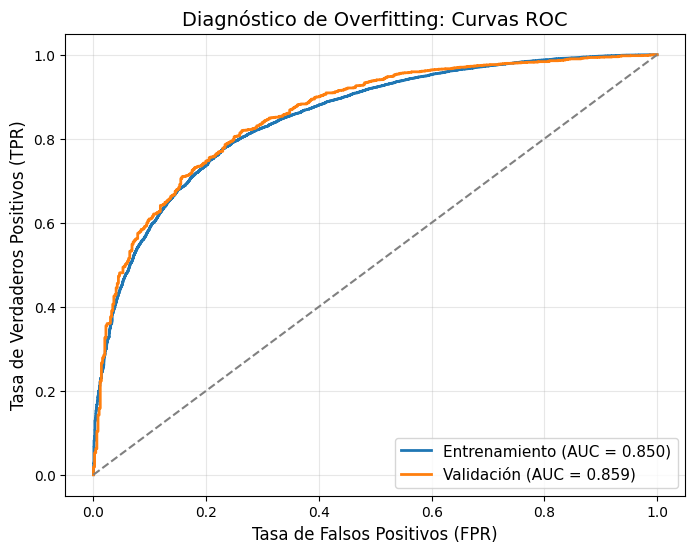

----------------------------------------
Diferencia de AUC: -0.008


In [ ]:
probabilidades_train = modelo.predict_proba(X_train)[:, 1]
fpr_train, tpr_train, _ = roc_curve(y_train, probabilidades_train)
fpr_val, tpr_val, _ = roc_curve(y_val, probabilidades_val)

auc_train = roc_auc_score(y_train, probabilidades_train)
auc_val = roc_auc_score(y_val, probabilidades_val)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, color='#1f77b4', linewidth=2,
         label=f'Entrenamiento (AUC = {auc_train:.3f})')
plt.plot(fpr_val, tpr_val, color='#ff7f0e', linewidth=2,
         label=f'Validación (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.title('Diagnóstico de Overfitting: Curvas ROC', fontsize=14)
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.show()

diferencia = auc_train - auc_val
print("-" * 40)
print(f"Diferencia de AUC: {diferencia:.3f}")

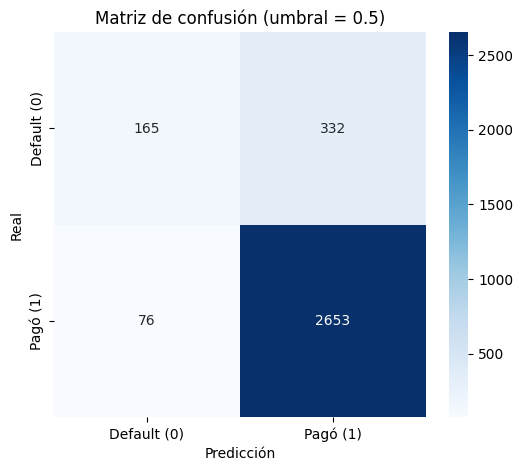

In [ ]:
umbral = 0.5
y_pred_val = (probabilidades_val >= umbral).astype(int)

cm = confusion_matrix(y_val, y_pred_val)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Default (0)", "Pagó (1)"],
            yticklabels=["Default (0)", "Pagó (1)"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión (umbral = {umbral})")
plt.show()

In [ ]:
## 8. Predicción sobre test y decisión de aprobación

In [ ]:
columnas_a_borrar_test = ["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud"]
X_test = solicitudes_test.drop(columns=columnas_a_borrar_test + cols_monto)
X_test = X_test.reindex(columns=X.columns, fill_value=0)
modelo.fit(X, y)

probabilidades_test = modelo.predict_proba(X_test)[:, 1]
#probabilidades_test = ensemble.predict_proba(X_test)[:, 1]

In [ ]:
resultados = solicitudes_test[["ID_Solicitud", "Monto_Solicitado", "Tasa_Interes"]].copy()
resultados["Prob_Paga"] = probabilidades_test
resultados["Prob_Default"] = 1 - resultados["Prob_Paga"]

resultados["Ganancia_Esperada"] = (
    resultados["Prob_Paga"] * (resultados["Monto_Solicitado"] * resultados["Tasa_Interes"])
    - resultados["Prob_Default"] * resultados["Monto_Solicitado"]
)
resultados["ROI_Esperado"] = resultados["Ganancia_Esperada"] / resultados["Monto_Solicitado"]

resultados = resultados.sort_values("ROI_Esperado", ascending=False)

In [ ]:
PRESUPUESTO_MAX = 2000000

candidatos = resultados[resultados["ROI_Esperado"] > 0.02].copy()

candidatos["Monto_Acumulado"] = candidatos["Monto_Solicitado"].cumsum()

candidatos["Estado_Final"] = (candidatos["Monto_Acumulado"] <= PRESUPUESTO_MAX).astype(int)

resultados["Estado_Final"] = 0
resultados.loc[candidatos[candidatos["Estado_Final"] == 1].index, "Estado_Final"] = 1

In [ ]:
## 9. Archivo de entrega

In [ ]:
resultados = resultados.sort_values("ID_Solicitud")

entrega_final = resultados[["ID_Solicitud", "Estado_Final"]].rename(
    columns={"Estado_Final": "Decision_Aprobacion"}
)
entrega_final.to_csv("entrega_presta_match.csv", index=False)

In [ ]:
capital_invertido = resultados[resultados['Estado_Final'] == 1]['Monto_Solicitado'].sum()
ganancia_proyectada = resultados[resultados['Estado_Final'] == 1]['Ganancia_Esperada'].sum()

print(f"Total de préstamos aprobados: {entrega_final['Decision_Aprobacion'].sum()}")
print(f"Capital total a invertir: ${capital_invertido:,.2f} USD")
print(f"Presupuesto sobrante: ${PRESUPUESTO_MAX - capital_invertido:,.2f} USD")
print(f"Ganancia Neta Proyectada: ${ganancia_proyectada:,.2f} USD")

Total de préstamos aprobados: 767
Capital total a invertir: $1,995,100.00 USD
Presupuesto sobrante: $4,900.00 USD
Ganancia Neta Proyectada: $498,427.52 USD


In [ ]:
## 10. Decisión con ROI y presupuesto en validación

In [ ]:
MONTO_MAX_TEST = 11000
fraccion_presupuesto = 2_000_000 / solicitudes_test["Monto_Solicitado"].sum()

In [ ]:
val = solicitudes_train.iloc[idx_val][["Monto_Solicitado", "Tasa_Interes", "Estado_Final"]].copy()
val["p"] = probabilidades_val
val = val[val["Monto_Solicitado"] <= MONTO_MAX_TEST].copy()

val["roi"] = val["p"] * (1 + val["Tasa_Interes"]) - 1
val = val.sort_values("roi", ascending=False)

capital = val["Monto_Solicitado"].cumsum()
presupuesto_val = fraccion_presupuesto * val["Monto_Solicitado"].sum()

val["aprobado"] = ((val["roi"] > 0.02) & (capital <= presupuesto_val)).astype(int)

In [ ]:
PRESUPUESTO_MAXIMO = 2000000

candidatos = val[val["aprobado"] == 1].copy()

aprobados = []
capital_acumulado = 0

for idx, prestamo in candidatos.iterrows():
    monto = prestamo["Monto_Solicitado"]

    if capital_acumulado + monto <= PRESUPUESTO_MAXIMO:
        aprobados.append(idx)
        capital_acumulado += monto

val["aprobado"] = 0
val.loc[aprobados, "aprobado"] = 1

val["ganancia_real"] = np.where(val["Estado_Final"] == 1,
                                val["Monto_Solicitado"] * val["Tasa_Interes"],
                                -val["Monto_Solicitado"])
ap = val[val["aprobado"] == 1]
print(f"Aprobados: {len(ap)} | capital: {ap['Monto_Solicitado'].sum():,.0f} USD")
print(f"Defaults entre aprobados: {(ap['Estado_Final'] == 0).mean():.1%}")
print(f"Ganancia real: {ap['ganancia_real'].sum():,.0f} USD")

Aprobados: 285 | capital: 1,999,800 USD
Defaults entre aprobados: 0.4%
Ganancia real: 533,605 USD


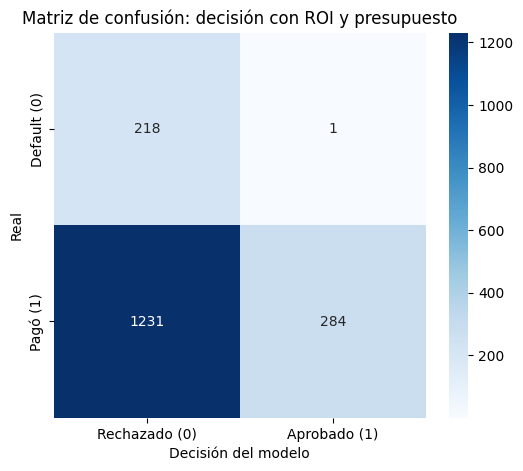

In [ ]:
cm_dec = confusion_matrix(val["Estado_Final"], val["aprobado"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_dec, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rechazado (0)", "Aprobado (1)"],
            yticklabels=["Default (0)", "Pagó (1)"])
plt.xlabel("Decisión del modelo")
plt.ylabel("Real")
plt.title("Matriz de confusión: decisión con ROI y presupuesto")
plt.show()

In [ ]:
usuarios_train = set(solicitudes_train["ID_Usuario"])
print("% de solicitudes de test cuyo usuario está en train:",
      solicitudes_test["ID_Usuario"].isin(usuarios_train).mean())
print("Fechas train:", solicitudes_train["Fecha_Solicitud"].min(), "→", solicitudes_train["Fecha_Solicitud"].max())
print("Fechas test: ", solicitudes_test["Fecha_Solicitud"].min(), "→", solicitudes_test["Fecha_Solicitud"].max())

% de solicitudes de test cuyo usuario está en train: 0.0
Fechas train: 2025-01 → 2025-12
Fechas test:  2026-01 → 2026-01


In [ ]:
print(solicitudes_train.assign(mes=fechas.dt.to_period("M"))
      .groupby("mes")["Estado_Final"].agg(["mean", "count"]))

cols = ["Monto_Solicitado", "Tasa_Interes", "Ingreso_Mensual"]
print(solicitudes_train[cols].describe())
print(solicitudes_test[cols].describe())
print("p media validación:", probabilidades_val.mean(),
      "| p media test:", probabilidades_test.mean())

             mean  count
mes                     
2025-01  0.840183   2628
2025-02  0.841357   2742
2025-03  0.845902   2745
2025-04  0.829907   2675
2025-05  0.830866   2702
2025-06  0.843956   2730
2025-07  0.840901   2709
2025-08  0.840058   2751
2025-09  0.844592   2709
2025-10  0.836832   2715
2025-11  0.848317   2703
2025-12  0.842731   2607
       Monto_Solicitado  Tasa_Interes  Ingreso_Mensual
count      32416.000000  32416.000000     32416.000000
mean       14290.097483      0.259580      4214.475938
std        12995.295179      0.032333      2498.904569
min          500.000000      0.147600       353.000000
25%         5700.000000      0.237300      2481.000000
50%        10200.000000      0.258300      3621.000000
75%        18100.000000      0.280600      5276.000000
max        70000.000000      0.379900     22000.000000
       Monto_Solicitado  Tasa_Interes  Ingreso_Mensual
count       3061.000000   3061.000000      3061.000000
mean        2235.315256      0.258836      42

In [ ]:
bins = pd.cut(solicitudes_train["Monto_Solicitado"], [0, 1000, 2000, 3000, 5000, 11000, 20000, 70000])
print(solicitudes_train.groupby(bins, observed=True)["Estado_Final"].agg(["mean", "count"]))
print("% de train con monto <= 11000:", (solicitudes_train["Monto_Solicitado"] <= 11000).mean())

                      mean  count
Monto_Solicitado                 
(0, 1000]         0.915152    165
(1000, 2000]      0.878547    881
(2000, 3000]      0.863055   1643
(3000, 5000]      0.882673   4040
(5000, 11000]     0.862361  10760
(11000, 20000]    0.828317   7974
(20000, 70000]    0.784122   6953
% de train con monto <= 11000: 0.5395175222112537


In [ ]:
chicos = solicitudes_train.iloc[idx_val]["Monto_Solicitado"].values <= 3000
print("n:", chicos.sum(),
      "| tasa de pago real:", y_val.values[chicos].mean(),
      "| p media predicha:", probabilidades_val[chicos].mean())

n: 268 | tasa de pago real: 0.8805970149253731 | p media predicha: 0.8595063471639751


In [ ]:
from sklearn.base import clone

modelos = {
    "HGB": lambda: clone(modelo),
    "RF": lambda: Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20,
                                      random_state=42, n_jobs=-1)),
    ]),
    "LogReg": lambda: Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000)),
    ]),
}

def metricas(p, va):
    v = solicitudes_train.iloc[va][["Monto_Solicitado", "Tasa_Interes", "Estado_Final"]].copy()
    v["p"] = p
    v = v[v["Monto_Solicitado"] <= 11000].copy()
    auc_v = roc_auc_score(v["Estado_Final"], v["p"])
    v["roi"] = v["p"] * (1 + v["Tasa_Interes"]) - 1
    v = v.sort_values("roi", ascending=False)
    cap = v["Monto_Solicitado"].cumsum()
    pres = fraccion_presupuesto * v["Monto_Solicitado"].sum()
    ap = v[(v["roi"] > 0.02) & (cap <= pres)]
    g = np.where(ap["Estado_Final"] == 1,
                 ap["Monto_Solicitado"] * ap["Tasa_Interes"],
                 -ap["Monto_Solicitado"])
    return {"AUC": auc_v, "aprobados": len(ap),
            "defaults": (ap["Estado_Final"] == 0).mean(),
            "ganancia_por_dolar": g.sum() / ap["Monto_Solicitado"].sum()}

fechas_tr = pd.to_datetime(solicitudes_train["Fecha_Solicitud"])
filas = []

for corte in ["2025-07-01", "2025-09-01", "2025-10-01"]:
    tr = np.where(fechas_tr < pd.Timestamp(corte))[0]
    va = np.where(fechas_tr >= pd.Timestamp(corte))[0]
    usuarios = set(solicitudes_train.iloc[tr]["ID_Usuario"])
    va = va[~solicitudes_train.iloc[va]["ID_Usuario"].isin(usuarios).values]

    probs = {}
    for nombre, crear in modelos.items():
        m = crear().fit(X.iloc[tr], y.iloc[tr])
        probs[nombre] = m.predict_proba(X.iloc[va])[:, 1]
    probs["HGB+RF"] = (probs["HGB"] + probs["RF"]) / 2

    for nombre, p in probs.items():
        filas.append({"corte": corte, "modelo": nombre, **metricas(p, va)})

res = pd.DataFrame(filas)
print(res.round(3).to_string(index=False))
print()
print(res.groupby("modelo")[["AUC", "defaults", "ganancia_por_dolar"]]
      .mean().round(3).sort_values("ganancia_por_dolar", ascending=False))

     corte modelo   AUC  aprobados  defaults  ganancia_por_dolar
2025-07-01    HGB 0.832       1296     0.022               0.239
2025-07-01     RF 0.828       1273     0.023               0.236
2025-07-01 LogReg 0.832       1277     0.021               0.233
2025-07-01 HGB+RF 0.830       1277     0.021               0.239
2025-09-01    HGB 0.853        686     0.010               0.252
2025-09-01     RF 0.851        676     0.012               0.251
2025-09-01 LogReg 0.851        683     0.012               0.245
2025-09-01 HGB+RF 0.852        678     0.010               0.252
2025-10-01    HGB 0.849        462     0.011               0.253
2025-10-01     RF 0.849        455     0.011               0.251
2025-10-01 LogReg 0.851        456     0.007               0.251
2025-10-01 HGB+RF 0.850        456     0.009               0.254

          AUC  defaults  ganancia_por_dolar
modelo                                     
HGB     0.844     0.014               0.248
HGB+RF  0.844     0.01

In [ ]:
filas = []
for corte in ["2025-07-01", "2025-09-01", "2025-10-01"]:
    tr = np.where(fechas_tr < pd.Timestamp(corte))[0]
    va = np.where(fechas_tr >= pd.Timestamp(corte))[0]
    usuarios = set(solicitudes_train.iloc[tr]["ID_Usuario"])
    va = va[~solicitudes_train.iloc[va]["ID_Usuario"].isin(usuarios).values]

    for d in [3, 4, 6, 8]:
        m = clone(modelo).set_params(max_depth=d).fit(X.iloc[tr], y.iloc[tr])
        p_tr = m.predict_proba(X.iloc[tr])[:, 1]
        p_va = m.predict_proba(X.iloc[va])[:, 1]
        r = metricas(p_va, va)
        filas.append({"corte": corte, "max_depth": d, "AUC_val": r["AUC"],
                      "brecha": roc_auc_score(y.iloc[tr], p_tr) - roc_auc_score(y.iloc[va], p_va),
                      "defaults": r["defaults"], "ganancia_por_dolar": r["ganancia_por_dolar"]})

res_d = pd.DataFrame(filas)
print(res_d.round(3).to_string(index=False))
print()
print(res_d.groupby("max_depth")[["AUC_val", "brecha", "defaults", "ganancia_por_dolar"]].mean().round(3))

     corte  max_depth  AUC_val  brecha  defaults  ganancia_por_dolar
2025-07-01          3    0.832   0.022     0.022               0.239
2025-07-01          4    0.829   0.030     0.022               0.238
2025-07-01          6    0.828   0.052     0.022               0.238
2025-07-01          8    0.828   0.059     0.022               0.240
2025-09-01          3    0.853  -0.001     0.010               0.252
2025-09-01          4    0.852   0.010     0.012               0.250
2025-09-01          6    0.850   0.030     0.013               0.248
2025-09-01          8    0.850   0.034     0.013               0.251
2025-10-01          3    0.849  -0.008     0.011               0.253
2025-10-01          4    0.847   0.000     0.011               0.253
2025-10-01          6    0.847   0.017     0.009               0.253
2025-10-01          8    0.847   0.024     0.009               0.253

           AUC_val  brecha  defaults  ganancia_por_dolar
max_depth                                    